In [15]:
import importlib
import src.lithology.models.trainer as trainer_module

importlib.reload(trainer_module)

train_models = trainer_module.train_models
evaluate_model = trainer_module.evaluate_model

In [16]:
results, scores, best_name = train_models(
    trainer.X_bal,
    trainer.X_test,
    trainer.y_bal,
    trainer.y_test,
    PROJECT_ROOT / "artifacts" / "models"
)

scores

c:\Users\Tammy\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,Accuracy
Random Forest,0.998836
XGBoost,0.996508
Logistic Regression,0.797439


In [17]:
best_name

'Random Forest'

              precision    recall  f1-score   support

  Clean Sand       1.00      1.00      1.00       631
  Silty Sand       1.00      1.00      1.00       469
 Sandy Shale       0.99      1.00      1.00       336
       Shale       1.00      1.00      1.00       282

    accuracy                           1.00      1718
   macro avg       1.00      1.00      1.00      1718
weighted avg       1.00      1.00      1.00      1718



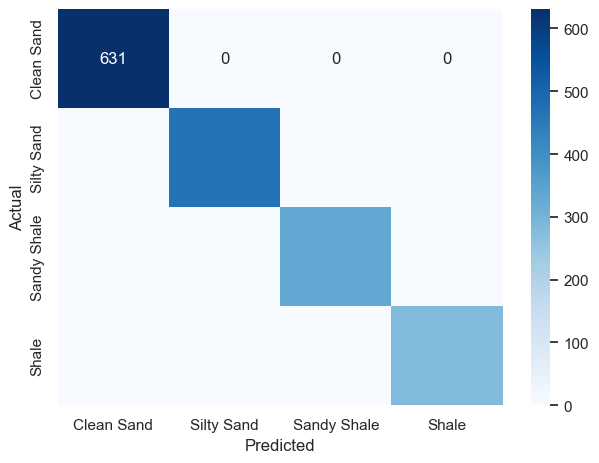

In [18]:
evaluate_model(
    trainer.y_test,
    results[best_name]["predictions"],
    PROJECT_ROOT / "outputs" / "reports"
)

In [19]:
scores

,Accuracy
Random Forest,0.998836
XGBoost,0.996508
Logistic Regression,0.797439


In [24]:
import importlib
import src.lithology.models.trainer as trainer_module

importlib.reload(trainer_module)

train_models = trainer_module.train_models
train_vsh_model = trainer_module.train_vsh_model
evaluate_model = trainer_module.evaluate_model


In [25]:
results, scores, best_name = train_models(
    trainer.X_bal,
    trainer.X_test,
    trainer.y_bal,
    trainer.y_test,
    PROJECT_ROOT / "artifacts" / "models"
)

scores


c:\Users\Tammy\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,Accuracy
Random Forest,0.998836
XGBoost,0.996508
Logistic Regression,0.797439


In [26]:
vsh_model, vsh_predictions, vsh_metrics = train_vsh_model(
    trainer.X_train,
    trainer.X_test,
    df.loc[trainer.X_train.index, "Vsh_PreTertiary"],
    df.loc[trainer.X_test.index, "Vsh_PreTertiary"],
    PROJECT_ROOT / "artifacts" / "models"
)

pd.DataFrame([vsh_metrics])


,R2,MAE,RMSE
0,1.0,0.000092,0.000164


In [27]:
from sklearn.metrics import accuracy_score, precision_score, f1_score

y_true = trainer.y_test
y_pred = results["Random Forest"]["predictions"]

print("Accuracy:", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred, average="weighted"))
print("F1 Score:", f1_score(y_true, y_pred, average="weighted"))

Accuracy: 0.9988358556461001
Precision: 0.9988427440742297
F1 Score: 0.9988367553211024
